This document contains instructions on how to generate plots of different filter transfer functions in 3D, more specifically:
| Name       | Type      | Order |
|------------|-----------|-------|
| $H_{hpf_2}$ | high-pass | 2nd   |
| $H_{lpf_2}$ | low-pass  | 2nd   |
| $H_{bpf_2}$ | band-pass | 2nd   |
| $H_{bpf_4}$ | band-pass | 4th   |

In [21]:
## IPython magic
%matplotlib inline

## Libraries
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

In [22]:
## Functions
def H_hpf_2(sigma, omega):
    return 20 * np.log((np.power(omega, 2) + np.power(sigma, 2)) / np.sqrt(5.656854248 * np.power(omega, 2) * sigma + 5.656854248 * np.power(sigma, 3) + 22.62741699 * sigma + np.power(sigma, 4) + (2 * np.power(omega, 2) + 16) * np.power(sigma, 2) + np.power(omega, 4) + 16))

def H_lpf_2(sigma, omega):
    return 20 * np.log(4 / np.sqrt(5.656854248 * np.power(omega, 2) * sigma + 5.656854248 * np.power(sigma, 3) + 22.62741699 * sigma + np.power(sigma, 4) + (2 * np.power(omega, 2) + 16) * np.power(sigma, 2) + np.power(omega, 4) + 16))

def H_bpf_2(sigma, omega):
    return 20 * np.log(2.828427124 * np.sqrt(np.power(omega, 2) + np.power(sigma, 2)) * np.sqrt(1 / (5.656854248 * np.power(omega, 2) * sigma + 5.656854248 * np.power(sigma, 3) + 22.62741699 * sigma + np.power(sigma, 4) + (2 * np.power(omega, 2) + 16) * np.power(sigma, 2) + np.power(omega, 4) + 16.)))

def H_bpf_4(sigma, omega):
    return 20 * np.log((9 * np.power(omega, 2) + 9 * np.power(sigma, 2)) / np.sqrt(14.14213562 * (np.power(sigma, 4) + (2 * np.power(omega, 2) + 25) * np.power(sigma, 2) + np.power(omega, 4) + np.power(omega, 2) + 36)*(np.power(omega, 2) + np.power(sigma, 2) + 6) * sigma + np.power(sigma, 8) + (4 * np.power(omega, 2) + 100) * np.power(sigma, 6) + (6 * np.power(omega, 4) + 200 * np.power(omega, 2) + 1297) * np.power(sigma, 4) + (4 * np.power(omega, 6) + 100 * np.power(omega, 4) + 818 * np.power(omega, 2) + 3600 ) * np.power(sigma, 2) + np.power(omega, 8) + 97* np.power(omega, 4) + 1296))

## Function names array
fn_arr=[
        [H_hpf_2, '$H_{hpf\_2}(s)$', 'H_hpf_2'],
        [H_lpf_2, '$H_{lpf\_2}(s)$', 'H_lpf_2'],
        [H_bpf_2, '$H_{bpf\_2}(s)$', 'H_bpf_2'],
        [H_bpf_4, '$H_{bpf\_4}(s)$', 'H_bpf_4']]

In [23]:
## Define ranges
x = np.linspace(-5, 5, 150)
y = np.linspace(-5, 5, 150)
X, Y = np.meshgrid(x, y)

x_log = np.linspace(-100, 100, 150)
y_log = np.linspace(np.log(1), np.log(200), 150)
X_log, Y_log = np.meshgrid(x_log, y_log)

H_hpf_2 = [min: -150.11793358761787,	max: 71.59119053267068]
H_lpf_2 = [min: -56.265752987951565,	max: 70.78646525658145]
H_bpf_2 = [min: -68.3648221114679,	max: 78.12029969494917]
H_bpf_4 = [min: -150.4343382284746,	max: 125.1433350417171]


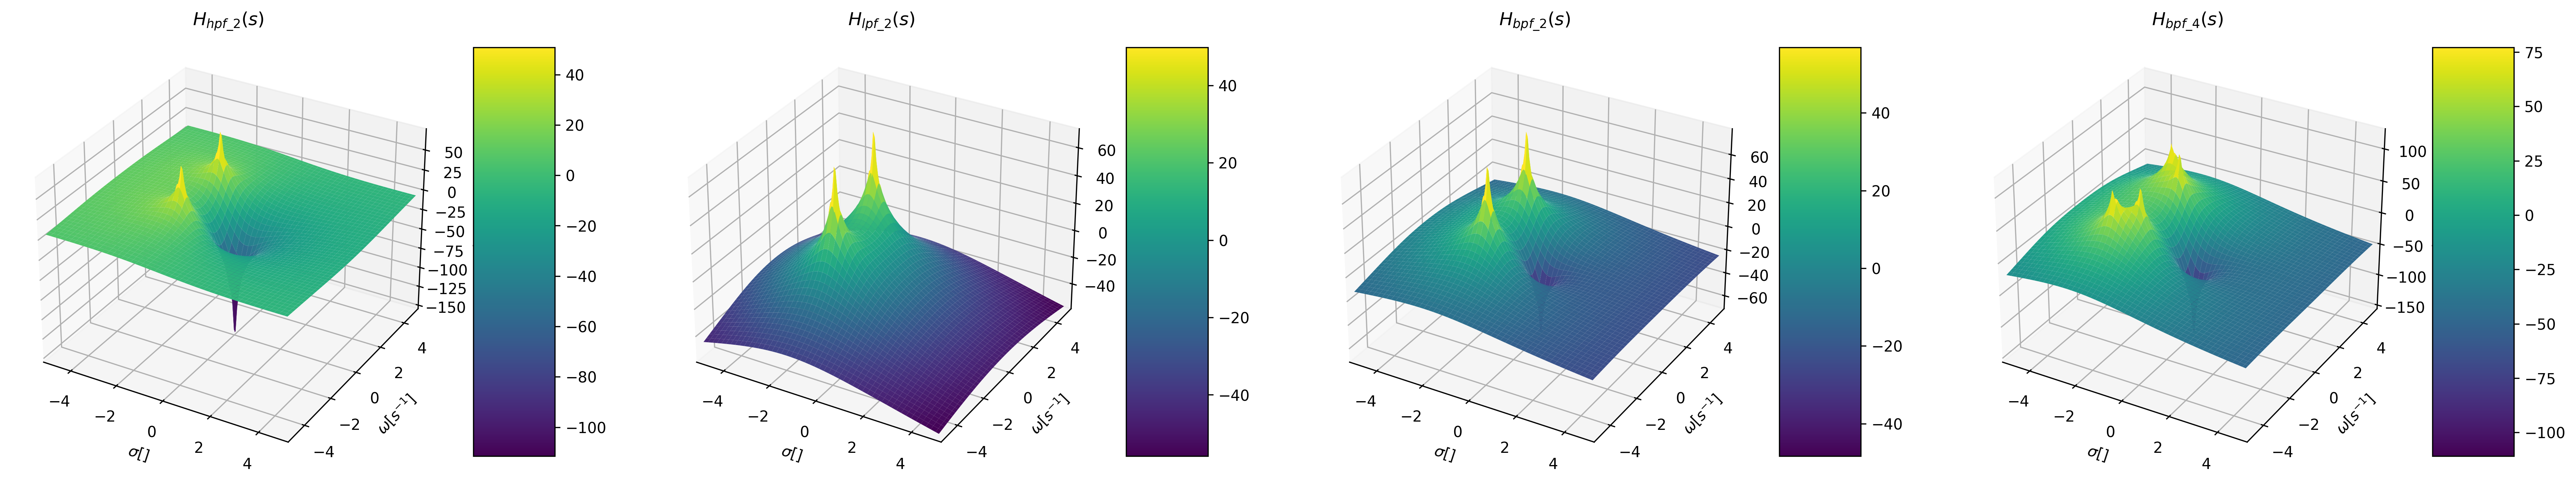

In [24]:
## Plot size
fig = plt.figure(dpi=300, figsize=[30,30])

for fn_num in range(len(fn_arr)):
    # Calculate values of function
    Z = np.array(fn_arr[fn_num][0](X, Y))
    X_flat = X.flatten()
    Y_flat = Y.flatten()
    Z_flat = Z.flatten()
    D_flat = np.transpose(np.vstack([X.flatten(), Y.flatten(), Z.flatten()]))
    
    # Dump values in a .csv file
    pd.DataFrame(D_flat).to_csv(fn_arr[fn_num][2] + ".csv", header=False, index=False)
    print(fn_arr[fn_num][2] + ' = [min: ' + str(np.min(Z)) + ',' + "\t" + 'max: ' + str(np.max(Z)) + ']')

    # Generate plot preview
    ax = fig.add_subplot(1, 4, fn_num+1, projection='3d')
    surf = ax.plot_surface(X, Y, Z,cmap='viridis')
    ax.set_title(fn_arr[fn_num][1])
    fig.colorbar(surf ,ax=ax, shrink=0.5, aspect=5)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_zlim(np.min(Z), np.max(Z))
    ax.set_xlabel('$\sigma[]$')
    ax.set_ylabel('$\omega[s^{-1}]$')
    ax.set_zlabel('$|H(s)|[dB]$')
plt.show()